<a href="https://colab.research.google.com/github/mxoizzz/helmet-detection-cnn/blob/main/helmet_cnn_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Automated Two-Wheeler Helmet Detection Using a CNN

Binary image classification: **Class 0 = With_Helmet**, **Class 1 = Without_Helmet**.

Pipeline: download dataset, build class folders from the label file, train a Keras Sequential CNN (64x64x3 input), evaluate, save.

## 1. Install dependencies

In [1]:
%pip install -q roboflow pandas scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 373.9/373.9 kB 11.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 36.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.4/58.4 kB 2.3 MB/s eta 0:00:00


## 2. Download the dataset from Roboflow

The API key is requested at run time (or read from Colab Secrets under the name `ROBOFLOW_API_KEY`). Do not paste a key directly into a notebook you share or submit.

In [2]:
import os
import shutil
import getpass
from roboflow import Roboflow

try:
    from google.colab import userdata
    API_KEY = userdata.get("TLu9Jbp93CYjdJAkuUqU")
except Exception:
    API_KEY = getpass.getpass("Roboflow API key: ")

rf = Roboflow(api_key=API_KEY)
project = rf.workspace("bike-helmets").project("bike-helmet-detection-2vdjo")
dataset = project.version(1).download("multiclass")

RAW_DIR = dataset.location
print("Downloaded to:", RAW_DIR)

Roboflow API key: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Bike-Helmet-Detection-1 in multiclass:: 100%|██████████| 1379/1379 [00:00<00:00, 1455.41it/s]

Downloaded to: /content/Bike-Helmet-Detection-1


## 3. Inspect the label files

The `multiclass` export stores all images of a split in one flat folder and the labels in `_classes.csv` (one column per class, 1 = present). There are no class sub-folders, so the folders have to be built from the CSV.

In [3]:
import pandas as pd
from IPython.display import display

for split in ["train", "valid", "test"]:
    csv_path = os.path.join(RAW_DIR, split, "_classes.csv")
    if os.path.exists(csv_path):
        df = pd.read_csv(csv_path)
        df.columns = [c.strip() for c in df.columns]
        print(f"{split}: {df.shape[0]} rows, columns = {list(df.columns)}")
        display(df.head(3))
    else:
        print(f"{split}: no _classes.csv found")

train: 1182 rows, columns = ['filename', 'With Helmet', 'Without Helmet']


,filename,With Helmet,Without Helmet
0,BikesHelmets558_png_jpg.rf.01c9f5f28b022201bef...,1,1
1,BikesHelmets143_png_jpg.rf.0290570305b3c527f1c...,1,1
2,BikesHelmets425_png_jpg.rf.0410d6ddd3ea1b476e8...,1,0


valid: 126 rows, columns = ['filename', 'With Helmet', 'Without Helmet']


,filename,With Helmet,Without Helmet
0,BikesHelmets527_png_jpg.rf.0d756da494fd8f06dcb...,1,0
1,BikesHelmets573_png_jpg.rf.12ad526ecd8addfca3f...,1,0
2,BikesHelmets325_png_jpg.rf.20521ff77f7fb5d5d3e...,0,1


test: 63 rows, columns = ['filename', 'With Helmet', 'Without Helmet']


,filename,With Helmet,Without Helmet
0,BikesHelmets55_png_jpg.rf.1041fa060d450bf55a8d...,0,1
1,BikesHelmets220_png_jpg.rf.2511258c37c57287f2b...,1,1
2,BikesHelmets340_png_jpg.rf.0a5d73c0d1949832e52...,1,1


## 4. Build the `helmet_dataset` folders (With_Helmet / Without_Helmet)

Class columns are detected automatically from their names. If detection fails, set `WITH_COL` and `WITHOUT_COL` manually to the column names printed above. Images are copied (the raw download stays untouched), and the two classes are balanced, capped at `MAX_PER_CLASS` images each.

In [4]:
import random

DATA_DIR = "helmet_dataset"
CLASS_NAMES = ["With_Helmet", "Without_Helmet"]   # index 0, index 1
MAX_PER_CLASS = 1000      # set to None to keep every available image
SEED = 42

WITH_COL = None           # e.g. "helmet"
WITHOUT_COL = None        # e.g. "no-helmet"


def detect_columns(columns):
    cols = [c for c in columns if c.lower() not in ("filename", "file_name", "image")]
    without_keys = ("without", "no helmet", "no-helmet", "no_helmet", "nohelmet", "non")
    without = [c for c in cols if any(k in c.lower() for k in without_keys)]
    with_ = [c for c in cols if c not in without and "helmet" in c.lower()]
    return with_, without


records = {0: [], 1: []}          # label -> list of (source_path, destination_name)

for split in ["train", "valid", "test"]:
    split_dir = os.path.join(RAW_DIR, split)
    csv_path = os.path.join(split_dir, "_classes.csv")
    if not os.path.exists(csv_path):
        continue

    df = pd.read_csv(csv_path)
    df.columns = [c.strip() for c in df.columns]
    file_col = df.columns[0]

    with_cols = [WITH_COL] if WITH_COL else detect_columns(df.columns)[0]
    without_cols = [WITHOUT_COL] if WITHOUT_COL else detect_columns(df.columns)[1]
    if not with_cols or not without_cols:
        raise ValueError(
            "Could not tell which columns are With_Helmet / Without_Helmet. "
            f"Columns found: {list(df.columns)}. Set WITH_COL and WITHOUT_COL manually."
        )

    for _, row in df.iterrows():
        is_without = any(row[c] == 1 for c in without_cols)
        is_with = any(row[c] == 1 for c in with_cols)
        if is_without == is_with:      # both or neither: ambiguous, skip
            continue
        label = 1 if is_without else 0
        src = os.path.join(split_dir, str(row[file_col]).strip())
        if os.path.exists(src):
            records[label].append((src, f"{split}_{os.path.basename(src)}"))

print("Available images  ->", CLASS_NAMES[0], len(records[0]), "|", CLASS_NAMES[1], len(records[1]))

n_per_class = min(len(records[0]), len(records[1]))
if MAX_PER_CLASS:
    n_per_class = min(n_per_class, MAX_PER_CLASS)
if n_per_class == 0:
    raise RuntimeError("No labelled images found. Check the column names printed in section 3.")

random.seed(SEED)
if os.path.exists(DATA_DIR):
    shutil.rmtree(DATA_DIR)

for label, class_name in enumerate(CLASS_NAMES):
    os.makedirs(os.path.join(DATA_DIR, class_name), exist_ok=True)
    for src, dst_name in random.sample(records[label], n_per_class):
        shutil.copy(src, os.path.join(DATA_DIR, class_name, dst_name))

for class_name in CLASS_NAMES:
    print(f"{class_name}: {len(os.listdir(os.path.join(DATA_DIR, class_name)))} images")

Available images  -> With_Helmet 837 | Without_Helmet 352
With_Helmet: 352 images
Without_Helmet: 352 images


## 5. Load the data (80% training / 20% validation, 64x64 RGB)

Found 704 files belonging to 2 classes.
Using 564 files for training.
Found 704 files belonging to 2 classes.
Using 140 files for validation.
Classes: ['With_Helmet', 'Without_Helmet']


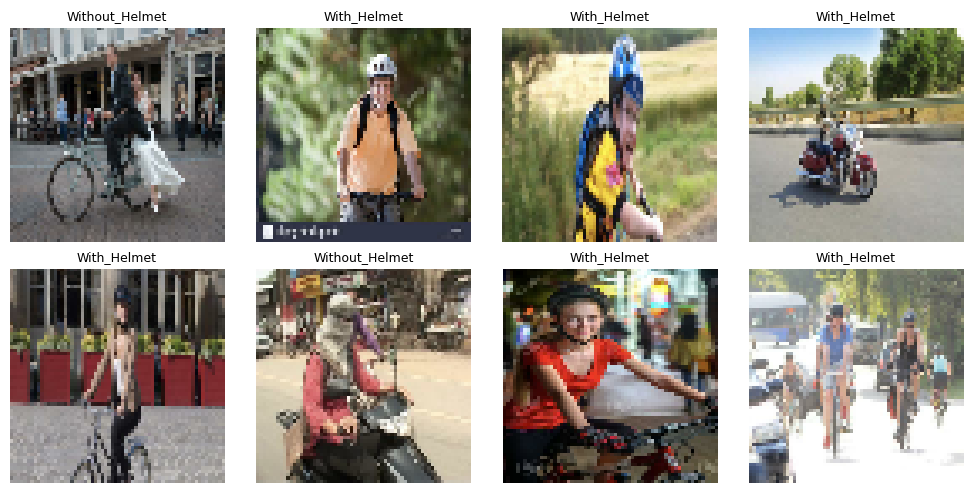

In [5]:
import numpy as np
import tensorflow as tf
import keras
from keras import layers
import matplotlib.pyplot as plt

IMG_SIZE = (64, 64)
BATCH_SIZE = 32
EPOCHS = 10

# Both calls use the same seed and the same default shuffle setting,
# so the training and validation subsets are disjoint.
common = dict(
    labels="inferred",
    label_mode="binary",          # labels are 0.0 / 1.0
    class_names=CLASS_NAMES,
    color_mode="rgb",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    seed=SEED,
)

train_ds = keras.utils.image_dataset_from_directory(DATA_DIR, subset="training", **common)
val_ds = keras.utils.image_dataset_from_directory(DATA_DIR, subset="validation", **common)

print("Classes:", train_ds.class_names)

# Preview a few training images
plt.figure(figsize=(10, 5))
for images, labels in train_ds.take(1):
    for i in range(8):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(CLASS_NAMES[int(labels[i][0])], fontsize=9)
        plt.axis("off")
plt.tight_layout()
plt.show()

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.cache().prefetch(tf.data.AUTOTUNE)

## 6. Build the CNN (Rescaling, Conv + Same padding + ReLU, Max Pooling, Flatten, Dense, Sigmoid)

In [6]:
model = keras.Sequential(
    [
        keras.Input(shape=(64, 64, 3)),
        layers.Rescaling(1.0 / 255),                                    # normalise pixels to 0-1
        layers.Conv2D(32, (3, 3), padding="same", activation="relu"),   # 64x64x32
        layers.MaxPooling2D((2, 2)),                                    # 32x32x32
        layers.Flatten(),                                               # 32,768 values
        layers.Dense(128, activation="relu"),
        layers.Dense(1, activation="sigmoid"),                          # probability of Without_Helmet
    ],
    name="helmet_cnn",
)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"],
)
model.summary()

Model: "helmet_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 64, 64, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,195,457 (16.00 MB)

 Trainable params: 4,195,457 (16.00 MB)

 Non-trainable params: 0 (0.00 B)

## 7. Train

In [7]:
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)

Epoch 1/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 341ms/step - accuracy: 0.4840 - loss: 1.2977 - val_accuracy: 0.5071 - val_loss: 0.7470
Epoch 2/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 155ms/step - accuracy: 0.5266 - loss: 0.7100 - val_accuracy: 0.4929 - val_loss: 0.6886
Epoch 3/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 161ms/step - accuracy: 0.5709 - loss: 0.6817 - val_accuracy: 0.6429 - val_loss: 0.6802
Epoch 4/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 218ms/step - accuracy: 0.7234 - loss: 0.6645 - val_accuracy: 0.5357 - val_loss: 0.6720
Epoch 5/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 155ms/step - accuracy: 0.7234 - loss: 0.6407 - val_accuracy: 0.6571 - val_loss: 0.6498
Epoch 6/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 3s 153ms/step - accuracy: 0.8209 - loss: 0.5924 - val_accuracy: 0.5786 - val_loss: 0.6339
Epoch 7/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 241ms/step - accuracy: 0.7270 - loss: 0.5574 - val_accuracy: 0.7429 - val_loss: 0.5794
Epoch 8/10
18/18 ━━━━━━━━━━━━━━━━━━━━ 4s 159ms/step - accuracy: 0.8670 - loss: 0.4432 - val_accuracy: 0

## 8. Evaluate

In [8]:
from sklearn.metrics import confusion_matrix, classification_report

train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)

final_train_acc = history.history["accuracy"][-1] * 100
final_val_acc = history.history["val_accuracy"][-1] * 100

print(f"Initial training loss : {history.history['loss'][0]:.4f}")
print(f"Final training loss   : {history.history['loss'][-1]:.4f}")
print(f"Training accuracy     : {final_train_acc:.1f}%")
print(f"Validation accuracy   : {final_val_acc:.1f}%")
print(f"Validation loss       : {val_loss:.4f}")
print(f"Generalisation gap    : {final_train_acc - final_val_acc:.1f} percentage points")

# Collect labels and predictions in a single pass so they stay aligned
y_true, y_prob = [], []
for images, labels in val_ds:
    y_true.append(labels.numpy().ravel())
    y_prob.append(model.predict_on_batch(images).ravel())
y_true = np.concatenate(y_true).astype(int)
y_prob = np.concatenate(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

print("\nConfusion matrix (rows = true, columns = predicted):")
print(confusion_matrix(y_true, y_pred))
print("\nClassification report:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=3))

Initial training loss : 1.2977
Final training loss   : 0.2884
Training accuracy     : 92.9%
Validation accuracy   : 83.6%
Validation loss       : 0.4214
Generalisation gap    : 9.3 percentage points

Confusion matrix (rows = true, columns = predicted):
[[62  7]
 [16 55]]

Classification report:
                precision    recall  f1-score   support

   With_Helmet      0.795     0.899     0.844        69
Without_Helmet      0.887     0.775     0.827        71

      accuracy                          0.836       140
     macro avg      0.841     0.837     0.835       140
  weighted avg      0.842     0.836     0.835       140



## 9. Learning curves

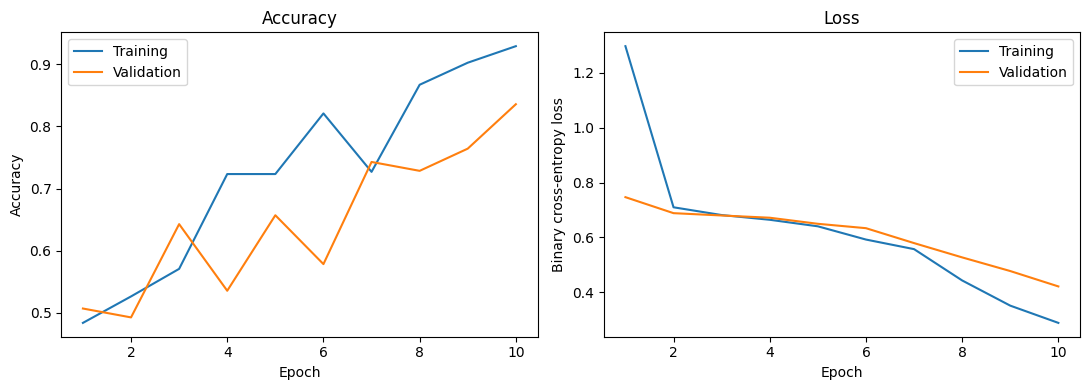

In [9]:
epochs_range = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(11, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history.history["accuracy"], label="Training")
plt.plot(epochs_range, history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history.history["loss"], label="Training")
plt.plot(epochs_range, history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Binary cross-entropy loss")
plt.title("Loss")
plt.legend()

plt.tight_layout()
plt.savefig("learning_curves.png", dpi=200)
plt.show()

## 10. Save the model and test predictions

Saved helmet_cnn.keras


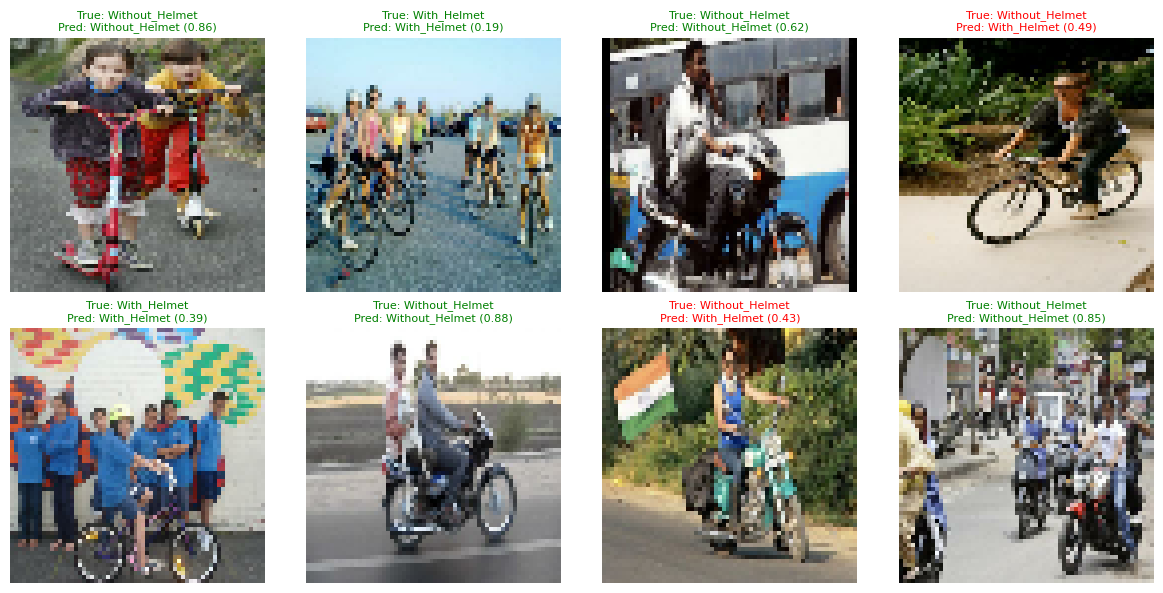

In [10]:
model.save("helmet_cnn.keras")
print("Saved helmet_cnn.keras")

# Show validation images with true and predicted labels
plt.figure(figsize=(12, 6))
for images, labels in val_ds.take(1):
    probs = model.predict_on_batch(images).ravel()
    for i in range(min(8, len(images))):
        pred = int(probs[i] >= 0.5)
        true = int(labels[i][0])
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        colour = "green" if pred == true else "red"
        plt.title(f"True: {CLASS_NAMES[true]}\nPred: {CLASS_NAMES[pred]} ({probs[i]:.2f})", fontsize=8, color=colour)
        plt.axis("off")
plt.tight_layout()
plt.show()


def predict_helmet(image_path, threshold=0.5):
    img = keras.utils.load_img(image_path, target_size=IMG_SIZE)
    arr = keras.utils.img_to_array(img)[np.newaxis, ...]       # shape (1, 64, 64, 3)
    p = float(model.predict(arr, verbose=0)[0][0])
    return CLASS_NAMES[int(p >= threshold)], p

# Example:
# label, prob = predict_helmet("path/to/rider_head.jpg")
# print(label, f"(P(Without_Helmet) = {prob:.3f})")